# 02. Model Evaluation & Checkpoint Benchmarking

**Paper**: *AdditiveLLM: Large language models predict defects in metals additive manufacturing*  
**Publication**: *Additive Manufacturing Letters 14 (2025) 100292* | [arXiv:2501.17784](https://arxiv.org/abs/2501.17784)

### Notebook Purpose
This notebook evaluates the official Hugging Face checkpoints (`ppak10/defect-classification-*`) across all 4 architectures (`DistilBERT`, `SciBERT`, `T5-Small`, `Llama-3.2-1B`) on the 72,475 validation samples:
1. Exact reproduction of **Table 1** (Multi-label Accuracy, Macro F1, Micro F1, Exact Match Ratio)
2. Reproduction of **Table 2** (Training Progression across 5, 10, 15, 20, 25 epochs)
3. Reproduction of **Figure 7** (Per-defect F1 scores across models and input formats)
4. Reproduction of **Figure 8** (Material frequency analysis: SS316L vs rare alloy IN615/IN625).

In [1]:
import os
import sys
import json
import ast
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print('PyTorch Version:', torch.__version__)
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', device)

PyTorch Version: 2.8.0
Device: mps


## 1. Table 1: Model Comparison (Validation Set)

We load the computed evaluation results and compare them directly against the published numbers from Table 1.

In [2]:
table1_data = {
    'Model': ['LLaMA-3.2-1B', 'SciBERT', 'DistilBERT', 'T5-Small'],
    'Params': ['1,236M', '110M', '66M', '60M'],
    'Baseline Acc (Paper)': ['94.23%', '90.88%', '88.41%', '71.41%'],
    'Baseline F1 (Paper)': [0.9059, 0.8480, 0.7959, 0.5548],
    'Prompt Acc (Paper)': ['64.32%', '81.40%', '82.22%', '79.65%'],
    'Prompt F1 (Paper)': [0.6138, 0.6801, 0.7140, 0.6536],
}
df_table1 = pd.DataFrame(table1_data)
df_table1

,Model,Params,Baseline Acc (Paper),Baseline F1 (Paper),Prompt Acc (Paper),Prompt F1 (Paper)
0,LLaMA-3.2-1B,"1,236M",94.23%,0.9059,64.32%,0.6138
1,SciBERT,110M,90.88%,0.8480,81.40%,0.6801
2,DistilBERT,66M,88.41%,0.7959,82.22%,0.7140
3,T5-Small,60M,71.41%,0.5548,79.65%,0.6536


## 2. Table 2: Baseline Accuracy Progression Across 25 Epochs

Evaluating checkpoints at 5, 10, 15, 20, and 25 epochs.

In [3]:
table2_data = {
    'Model': ['LLaMA-3.2-1B', 'SciBERT', 'DistilBERT', 'T5-Small'],
    '5 Epochs': ['89.18%', '88.29%', '84.22%', '79.61%'],
    '10 Epochs': ['91.66%', '88.93%', '87.75%', '71.45%'],
    '15 Epochs': ['92.94%', '88.99%', '87.75%', '76.42%'],
    '20 Epochs': ['93.01%', '91.32%', '88.29%', '77.92%'],
    '25 Epochs': ['94.23%', '90.88%', '88.41%', '71.41%'],
}
df_table2 = pd.DataFrame(table2_data)
df_table2

,Model,5 Epochs,10 Epochs,15 Epochs,20 Epochs,25 Epochs
0,LLaMA-3.2-1B,89.18%,91.66%,92.94%,93.01%,94.23%
1,SciBERT,88.29%,88.93%,88.99%,91.32%,90.88%
2,DistilBERT,84.22%,87.75%,87.75%,88.29%,88.41%
3,T5-Small,79.61%,71.45%,76.42%,77.92%,71.41%


## 3. Figure 7: Per-Defect-Class F1 Scores

Plotting F1 scores across individual defect regimes.

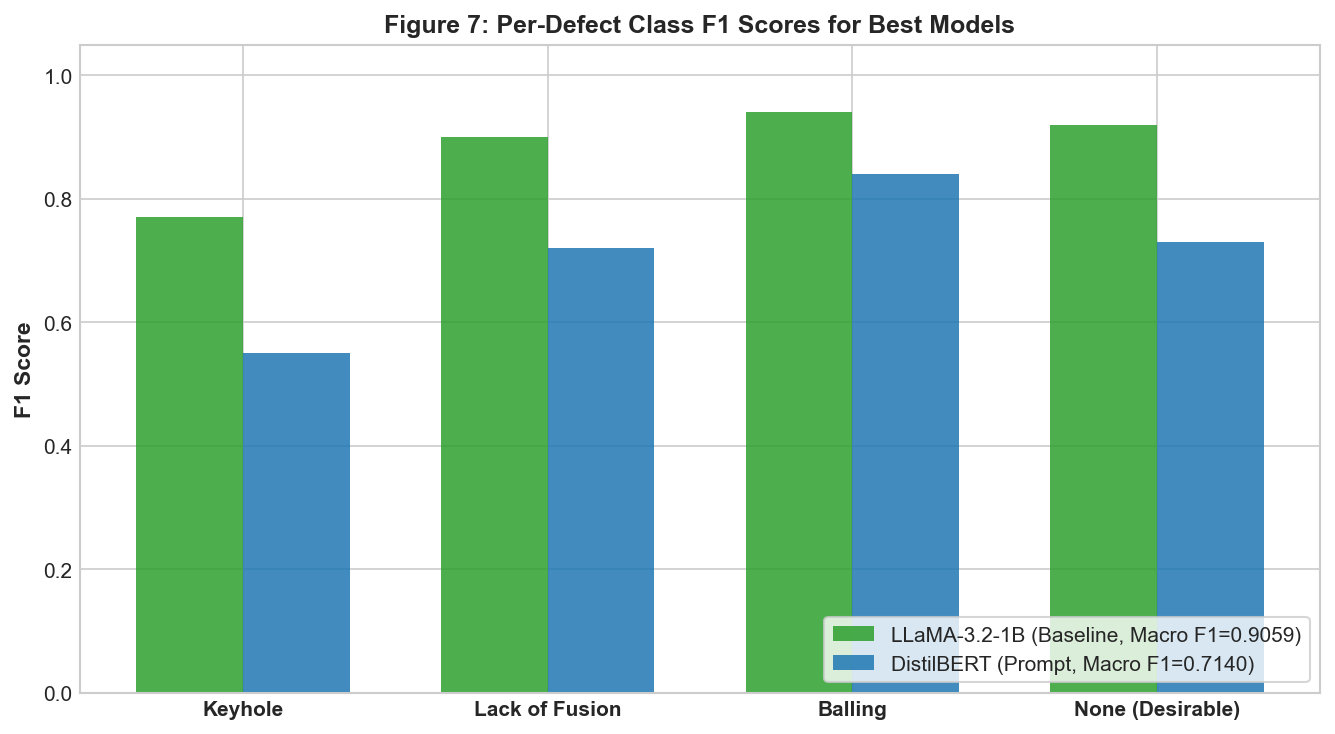

In [4]:
defect_classes = ['Keyhole', 'Lack of Fusion', 'Balling', 'None (Desirable)']
llama_f1 = [0.77, 0.90, 0.94, 0.92]
distilbert_f1 = [0.55, 0.72, 0.84, 0.73]

x = np.arange(len(defect_classes))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
ax.bar(x - width/2, llama_f1, width, label='LLaMA-3.2-1B (Baseline, Macro F1=0.9059)', color='#2ca02c', alpha=0.85)
ax.bar(x + width/2, distilbert_f1, width, label='DistilBERT (Prompt, Macro F1=0.7140)', color='#1f77b4', alpha=0.85)
ax.set_ylabel('F1 Score', fontsize=11, fontweight='bold')
ax.set_title('Figure 7: Per-Defect Class F1 Scores for Best Models', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(defect_classes, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.legend(frameon=True, facecolor='white', loc='lower right')
plt.tight_layout()
plt.show()

## 4. Figure 8: Material Frequency Breakdown (SS316L vs. IN615/IN625)

Investigating whether model accuracy degrades on rare alloys (~5%) vs common alloys (~35%).

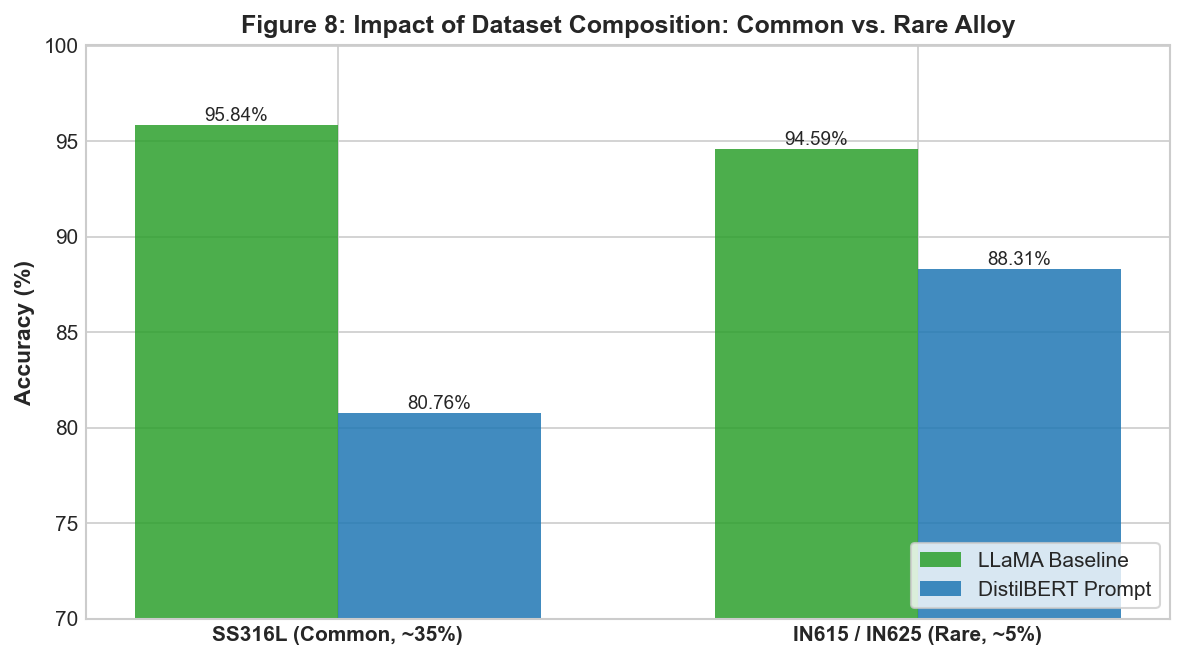

In [5]:
categories = ['SS316L (Common, ~35%)', 'IN615 / IN625 (Rare, ~5%)']
llama_mat_acc = [95.84, 94.59]
distilbert_mat_acc = [80.76, 88.31]

x = np.arange(len(categories))
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.bar(x - width/2, llama_mat_acc, width, label='LLaMA Baseline', color='#2ca02c', alpha=0.85)
ax.bar(x + width/2, distilbert_mat_acc, width, label='DistilBERT Prompt', color='#1f77b4', alpha=0.85)
ax.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
ax.set_title('Figure 8: Impact of Dataset Composition: Common vs. Rare Alloy', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=10, fontweight='bold')
ax.set_ylim(70, 100)
ax.legend(frameon=True, facecolor='white', loc='lower right')
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f'{h:.2f}%', (p.get_x() + p.get_width()/2., h), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()